Week 4-START

In [1]:
# Import libraries
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)

# Load the train and test sets saved in Week 3
PROCESSED_DIR = Path("../data/processed")
train = pd.read_csv(PROCESSED_DIR / "train.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")
print("Train:", train.shape, "| Test:", test.shape)

Train: (1792, 29) | Test: (448, 29)


### 1. Remove duplicates
In train, we drop customers whose copies have different Response labels, then keep one copy of each customer. In test, we only remove exact copies.

In [2]:
# Columns that describe the customer (everything except ID and the target)
feature_columns = [c for c in train.columns if c not in ("ID", "Response")]

# Train: drop duplicate groups whose copies have different Response labels
key = train[feature_columns].apply(lambda s: s.map(str)).agg("|".join, axis=1)
labels_per_group = train.groupby(key)["Response"].transform("nunique")
print("Train rows dropped (conflicting labels):", (labels_per_group > 1).sum())
train = train[labels_per_group == 1]

# Train: keep one copy of each remaining customer
before = len(train)
train = train.drop_duplicates(subset=feature_columns).reset_index(drop=True)
print("Train rows dropped (duplicates):", before - len(train))

# Test: remove exact copies only (same features and same label)
before = len(test)
test = test.drop_duplicates(subset=feature_columns + ["Response"]).reset_index(drop=True)
print("Test rows dropped (duplicates):", before - len(test))

Train rows dropped (conflicting labels): 34
Train rows dropped (duplicates): 144
Test rows dropped (duplicates): 36


### 2. Clean the data
- Drop ID, Z_CostContact, and Z_Revenue because they don't help prediction.
- Group marital status into partnered or not, since Married and Together respond at about 10% while Single, Divorced, and Widow respond at about 22%. Absurd and YOLO become missing.
- Merge "2n Cycle" into Master.
- Treat birth years before 1920 and the $666,666 income as missing.

In [3]:
def clean(df):
    # Drop the identifier and the two constant columns
    df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])

    # Group marital status into partnered (1) or not (0); Absurd and YOLO become missing
    partnered_map = {"Married": 1, "Together": 1,
                     "Single": 0, "Divorced": 0, "Widow": 0, "Alone": 0}
    df["Is_Partnered"] = df["Marital_Status"].map(partnered_map)
    df = df.drop(columns="Marital_Status")

    # 2n Cycle is a master's level degree
    df["Education"] = df["Education"].replace({"2n Cycle": "Master"})

    # Birth years before 1920 are data entry errors
    df.loc[df["Year_Birth"] < 1920, "Year_Birth"] = np.nan

    # $666,666 is a placeholder, not a real income
    df.loc[df["Income"] == 666666, "Income"] = np.nan

    # Convert enrollment date from text to a date
    df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
    return df

train = clean(train)
test = clean(test)
print("Missing values in train after cleaning:")
print(train.isnull().sum()[train.isnull().sum() > 0])

Missing values in train after cleaning:
Year_Birth       2
Income          17
Is_Partnered     2
dtype: int64


### 3. Remove inconsistent rows (train only)
In Week 3 we found 5 rows with spending but zero purchases, and 3 rows where deal purchases exceed total purchases. These numbers contradict each other, so we drop them from train. Test is left unchanged.

In [4]:
spend_columns = ["MntWines", "MntFruits", "MntMeatProducts",
                 "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
purchase_columns = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]

total_spend = train[spend_columns].sum(axis=1)
total_purchases = train[purchase_columns].sum(axis=1)

# Rows where spending and purchase counts contradict each other
bad_rows = ((total_spend > 0) & (total_purchases == 0)) | \
           (train["NumDealsPurchases"] > total_purchases)
print("Inconsistent training rows dropped:", bad_rows.sum())
train = train[~bad_rows].reset_index(drop=True)

Inconsistent training rows dropped: 6


### 4. Fill missing values
We did this after all rows are dropped, so the fill values come from the final training set. Income and birth year are filled with the training median, and the partnered flag with the most common value.

In [5]:
# Fill values are learned from the training set only
income_median = train["Income"].median()
birth_median = train["Year_Birth"].median()
partnered_mode = train["Is_Partnered"].mode()[0]

for df in (train, test):
    df["Income"] = df["Income"].fillna(income_median)
    df["Year_Birth"] = df["Year_Birth"].fillna(birth_median)
    df["Is_Partnered"] = df["Is_Partnered"].fillna(partnered_mode).astype(int)

print("Missing values left in train:", train.isnull().sum().sum())
print("Missing values left in test:", test.isnull().sum().sum())

Missing values left in train: 0
Missing values left in test: 0


### 5. Create new features
Age, tenure, total spend, total purchases, and total prior campaigns accepted. In Week 3  prior acceptances and tenure showed as strong signals for Response. Year_Birth and Dt_Customer are dropped after Age and Tenure are created. A Children column is not created because Kidhome and Teenhome affect response differently.

In [6]:
campaign_columns = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
                    "AcceptedCmp4", "AcceptedCmp5"]

# Reference date = latest enrollment in train (same date used for test)
reference_date = train["Dt_Customer"].max()

def add_features(df):
    df["Age"] = reference_date.year - df["Year_Birth"]
    df["Tenure_Days"] = (reference_date - df["Dt_Customer"]).dt.days
    df["Total_Spend"] = df[spend_columns].sum(axis=1)
    df["Total_Purchases"] = df[purchase_columns].sum(axis=1)
    df["Total_Prev_Accepted"] = df[campaign_columns].sum(axis=1)
    # Year_Birth and Dt_Customer are replaced by Age and Tenure_Days
    return df.drop(columns=["Year_Birth", "Dt_Customer"])

train = add_features(train)
test = add_features(test)
train[["Age", "Tenure_Days", "Total_Spend", "Total_Purchases",
       "Total_Prev_Accepted"]].describe().round(1)

,Age,Tenure_Days,Total_Spend,Total_Purchases,Total_Prev_Accepted
count,1608.0,1608.0,1608.0,1608.0,1608.0
mean,45.3,352.5,622.9,12.7,0.3
std,11.7,201.4,609.6,7.2,0.7
min,18.0,0.0,8.0,1.0,0.0
25%,37.0,180.0,70.0,6.0,0.0
50%,44.0,352.0,411.0,12.0,0.0
75%,55.0,525.0,1079.2,19.0,0.0
max,74.0,699.0,2524.0,32.0,4.0


### 6. Log transform
In Week 3 we saw the spending columns, NumDealsPurchases, and NumCatalogPurchases are right skewed (skew above 1). A log transform reduces the effect of very large values without removing real high spenders. Income is not transformed: once the $666,666 placeholder is removed, its skew is only 0.29, and a log transform made it worse (-1.13).

In [7]:
log_columns = ["Total_Spend", "NumDealsPurchases", "NumCatalogPurchases"] + spend_columns

print("Skew before:")
print(train[log_columns].skew().round(2))

for df in (train, test):
    df[log_columns] = np.log1p(df[log_columns])

print("\nSkew after:")
print(train[log_columns].skew().round(2))

Skew before:
Total_Spend            0.81
NumDealsPurchases      2.29
NumCatalogPurchases    2.08
MntWines               1.13
MntFruits              2.07
MntMeatProducts        2.11
MntFishProducts        1.84
MntSweetProducts       2.06
MntGoldProds           1.83
dtype: float64

Skew after:
Total_Spend           -0.39
NumDealsPurchases      0.68
NumCatalogPurchases    0.11
MntWines              -0.58
MntFruits              0.05
MntMeatProducts       -0.12
MntFishProducts       -0.07
MntSweetProducts       0.05
MntGoldProds          -0.37
dtype: float64


### 7. One hot encode education
Each education level becomes its own 0/1 column, so the model doesn't assume equal gaps between degree levels. Basic is dropped and used as the baseline.

In [8]:
# Basic is dropped and becomes the baseline category
train = pd.get_dummies(train, columns=["Education"], prefix="Edu",
                       drop_first=True, dtype=int)
test = pd.get_dummies(test, columns=["Education"], prefix="Edu",
                      drop_first=True, dtype=int)

# Make sure test has exactly the same columns as train
test = test.reindex(columns=train.columns, fill_value=0)
print("Education columns:", [c for c in train.columns if c.startswith("Edu")])

Education columns: ['Edu_Graduation', 'Edu_Master', 'Edu_PhD']


### 8. Standardize
Numeric columns are scaled to mean 0 and standard deviation 1, so features in different units are comparable. 0/1 columns and the target are not scaled. The scaler is fit on train only.

In [9]:
# Binary (0/1) columns and the target are not scaled
binary_columns = [c for c in train.columns if set(train[c].unique()) <= {0, 1}]
scale_columns = [c for c in train.columns if c not in binary_columns]

scaler = StandardScaler()
train[scale_columns] = scaler.fit_transform(train[scale_columns])
test[scale_columns] = scaler.transform(test[scale_columns])

print("Scaled columns:", scale_columns)
train[scale_columns].describe().round(2)

Scaled columns: ['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'Age', 'Tenure_Days', 'Total_Spend', 'Total_Purchases', 'Total_Prev_Accepted']


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Age,Tenure_Days,Total_Spend,Total_Purchases,Total_Prev_Accepted
count,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00
mean,0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.35,-0.83,-0.92,-1.72,-2.60,-1.45,-2.65,-1.54,-1.43,-2.44,-2.31,-1.52,-1.32,-1.79,-2.24,-2.35,-1.75,-2.34,-1.62,-0.44
25%,-0.78,-0.83,-0.92,-0.86,-0.82,-0.75,-0.85,-0.71,-0.99,-0.65,-0.82,-0.78,-1.32,-0.87,-0.97,-0.72,-0.86,-0.94,-0.93,-0.44
50%,-0.00,-0.83,-0.92,0.00,0.28,0.02,0.07,0.00,0.02,0.13,0.05,-0.04,0.10,-0.25,0.30,-0.11,-0.00,0.25,-0.09,-0.44
75%,0.78,1.01,0.91,0.90,0.85,0.83,0.84,0.84,0.82,0.71,0.67,0.70,0.76,0.67,0.73,0.83,0.86,0.90,0.88,-0.44
max,5.19,2.86,2.74,1.69,1.44,1.92,2.08,1.79,1.89,2.06,3.64,7.76,3.03,2.20,6.24,2.46,1.72,1.48,2.69,5.31


# Week 5 – Feature Engineering, Data Augmentation, Dimensionality Reduction
### A. Combined features
We built five candidate features from two or more fields:
- **Household_Size** = 1 + Is_Partnered + Kidhome + Teenhome
- **Lives_Alone** = single (not partnered) with no children at home
- **Income_per_Person** = Income / household size
- **Catalog_Share** = catalog purchases / total purchases (channel preference)
- **Deal_Share** = deal purchases / total purchases (price sensitivity)

Week 4 log-transformed and standardized several of the input columns, but ratios and household counts need the original values. So we first reverse those two Week 4 steps, build the features from the original values, and then standardize the new features with a scaler fit on the training set only. We also check that Kidhome and Teenhome don't count the same child twice.

In [10]:
# Additional imports for Week 5
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, learning_curve
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline

In [11]:
# Week 4 replaced several columns with log-transformed and standardized versions.
# Ratios and household counts need the ORIGINAL values, so we reverse those two steps
# (scaling first, then the log) using the Week 4 scaler, which was fit on train only.
def original_values(df):
    raw = df.copy()
    raw[scale_columns] = scaler.inverse_transform(df[scale_columns])
    raw[log_columns] = np.expm1(raw[log_columns])
    return raw

train_raw = original_values(train)
test_raw = original_values(test)

# Check the reversal is exact: count columns must come back as whole numbers
count_columns = ["Kidhome", "Teenhome", "NumCatalogPurchases", "NumDealsPurchases", "Total_Purchases", "Age"]
for raw in (train_raw, test_raw):
    largest_gap = (raw[count_columns] - raw[count_columns].round()).abs().max().max()
    assert largest_gap < 1e-6, largest_gap
    raw[count_columns] = raw[count_columns].round().astype(int)
print("Original values recovered for train and test (largest rounding gap < 0.000001)")

Original values recovered for train and test (largest rounding gap < 0.000001)


In [12]:
# Check: could a child be counted in both Kidhome and Teenhome?
# Kidhome = number of young children, Teenhome = number of teenagers. If they overlapped,
# customers with both would look implausible. Instead their age sits between the two groups,
# as expected for families with one younger and one older child.
children = pd.crosstab(train_raw["Kidhome"], train_raw["Teenhome"], margins=True)
print("Households by number of young children (rows) and teenagers (columns):")
print(children)

group = np.select([(train_raw["Kidhome"] > 0) & (train_raw["Teenhome"] > 0),
                   (train_raw["Kidhome"] > 0), (train_raw["Teenhome"] > 0)],
                  ["Young children and teens", "Young children only", "Teens only"],
                  default="No children")
print("\nMedian customer age by household type:")
print(train_raw.groupby(group)["Age"].agg(customers="count", median_age="median"))

Households by number of young children (rows) and teenagers (columns):
Teenhome    0    1   2   All
Kidhome                     
0         458  446  19   923
1         367  259  21   647
2          16   22   0    38
All       841  727  40  1608

Median customer age by household type:
                          customers  median_age
No children                     458        46.0
Teens only                      465        50.0
Young children and teens        302        48.0
Young children only             383        36.0


In [13]:
# Candidate combined features, built from the ORIGINAL values (not logged or scaled)
def candidate_features(raw):
    household = 1 + raw["Is_Partnered"] + raw["Kidhome"] + raw["Teenhome"]
    purchases = raw["Total_Purchases"].replace(0, np.nan)
    return pd.DataFrame({
        "Household_Size": household,                                    # customer + partner + children
        "Lives_Alone": ((raw["Is_Partnered"] == 0) &                    # single with no children at home
                        (raw["Kidhome"] + raw["Teenhome"] == 0)).astype(int),
        "Income_per_Person": raw["Income"] / household,                 # income spread across the household
        "Catalog_Share": raw["NumCatalogPurchases"] / purchases,        # channel preference
        "Deal_Share": raw["NumDealsPurchases"] / purchases,             # price sensitivity
    }, index=raw.index)

new_train = candidate_features(train_raw)
new_test = candidate_features(test_raw)
candidate_features_list = list(new_train.columns)

# One test customer has 0 recorded purchases, so the shares are undefined.
# Fill with the training median (learned from train only).
share_columns = ["Catalog_Share", "Deal_Share"]
print("Test rows with 0 purchases (shares filled):", int(new_test["Catalog_Share"].isna().sum()))
new_test[share_columns] = new_test[share_columns].fillna(new_train[share_columns].median())

# Standardize the four non-binary features the same way as Week 4 (scaler fit on train only)
new_scale_columns = ["Household_Size", "Income_per_Person", "Catalog_Share", "Deal_Share"]
new_scaler = StandardScaler()
new_train[new_scale_columns] = new_scaler.fit_transform(new_train[new_scale_columns])
new_test[new_scale_columns] = new_scaler.transform(new_test[new_scale_columns])

train = pd.concat([train, new_train], axis=1)
test = pd.concat([test, new_test], axis=1)
candidate_features = candidate_features_list

# Why Lives_Alone: response is not additive. Single customers with no children respond
# far more than either "single" or "no children" alone would suggest.
print("\nResponse rate (%) by partnered status and number of children:")
print((train_raw.pivot_table(index="Is_Partnered", columns=train_raw["Kidhome"] + train_raw["Teenhome"],
                             values="Response", aggfunc="mean") * 100).round(1))

# Exact duplicate information: is a column an exact sum of other columns (original values)?
# If the rank does not increase when the column is added, it adds no new linear information.
def adds_new_information(new_values, parts):
    base = np.column_stack([np.ones(len(train_raw))] + [train_raw[p] for p in parts])
    return np.linalg.matrix_rank(np.column_stack([base, new_values])) > np.linalg.matrix_rank(base)

household_raw = 1 + train_raw["Is_Partnered"] + train_raw["Kidhome"] + train_raw["Teenhome"]
print("\nAdds new linear information beyond its parts?")
print("  Household_Size vs Is_Partnered + Kidhome + Teenhome:",
      adds_new_information(household_raw, ["Is_Partnered", "Kidhome", "Teenhome"]))
print("  Total_Purchases (Week 4) vs web + catalog + store:",
      adds_new_information(train_raw["Total_Purchases"], purchase_columns))
print("  Total_Prev_Accepted (Week 4) vs the five campaign flags:",
      adds_new_information(train_raw["Total_Prev_Accepted"], campaign_columns))

Test rows with 0 purchases (shares filled): 1

Response rate (%) by partnered status and number of children:
                 0     1     2    3
Is_Partnered                       
0             41.2  13.9  15.8  5.9
1             15.9   8.5   7.0  3.8

Adds new linear information beyond its parts?
  Household_Size vs Is_Partnered + Kidhome + Teenhome: False
  Total_Purchases (Week 4) vs web + catalog + store: False
  Total_Prev_Accepted (Week 4) vs the five campaign flags: False


### B. Which combined features add value?
To see whether each candidate improved predictions, we added it on its own to the 30 Week 4 features and scored the result with 5-fold stratified cross-validation repeated 3 times (15 folds). We ran this on the **training set only**, so the test set stays untouched for the final evaluation.

We used a simple logistic regression as a consistent yardstick, not as the final model. We chose PR-AUC as the main metric because only 14.6% of training customers responded, which makes accuracy misleading. Random guessing would score a PR-AUC of about 0.15.

In [14]:
# Helper: cross-validation on the TRAINING SET ONLY (the test set stays untouched)
# 5 folds x 3 repeats = 15 folds. Every setup uses the same folds, so results can be
# compared fold by fold. Logistic regression is a simple, consistent yardstick here,
# not the final model.
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
X_all = train.drop(columns="Response")
y = train["Response"]
fold_pr = {}

def cv_scores(columns, label, model=None, n_features=None):
    model = model if model is not None else LogisticRegression(max_iter=2000)
    s = cross_validate(model, X_all[columns], y, cv=cv,
                       scoring={"PR-AUC": "average_precision", "ROC-AUC": "roc_auc"})
    fold_pr[label] = s["test_PR-AUC"]
    return {"setup": label, "features": n_features or len(columns),
            "PR-AUC": round(s["test_PR-AUC"].mean(), 3),
            "PR-AUC sd": round(s["test_PR-AUC"].std(), 3),
            "ROC-AUC": round(s["test_ROC-AUC"].mean(), 3)}

def vs(label, reference):
    diff = fold_pr[label] - fold_pr[reference]
    return round(diff.mean(), 3), int((diff > 0).sum())

week4_columns = [c for c in X_all.columns if c not in candidate_features]
print("Response rate in training data:", round(y.mean() * 100, 1), "% (= PR-AUC of random guessing)")

# Test each candidate by adding it alone to the Week 4 features
rows = [cv_scores(week4_columns, "Week 4 features")]
for c in candidate_features:
    rows.append(cv_scores(week4_columns + [c], "+ " + c))
rows[0]["change vs Week 4"], rows[0]["folds improved (of 15)"] = "-", "-"
for r in rows[1:]:
    change, wins = vs(r["setup"], "Week 4 features")
    r["change vs Week 4"], r["folds improved (of 15)"] = f"{change:+.3f}", str(wins)
print(pd.DataFrame(rows).to_string(index=False))

Response rate in training data: 14.6 % (= PR-AUC of random guessing)
              setup  features  PR-AUC  PR-AUC sd  ROC-AUC change vs Week 4 folds improved (of 15)
    Week 4 features        30   0.693      0.065    0.920                -                      -
   + Household_Size        31   0.693      0.065    0.920           +0.000                      9
      + Lives_Alone        31   0.713      0.066    0.926           +0.020                     13
+ Income_per_Person        31   0.726      0.065    0.929           +0.033                     15
    + Catalog_Share        31   0.691      0.067    0.920           -0.002                      3
       + Deal_Share        31   0.694      0.064    0.919           +0.002                     10


**Decision:** we kept **Income_per_Person** and **Lives_Alone**, the only two candidates that improved PR-AUC on most folds.
- We dropped **Household_Size** because it is an exact sum of Is_Partnered, Kidhome, and Teenhome, so it added no new information (+0.000).
- We dropped **Catalog_Share** and **Deal_Share** because they added almost nothing and largely repeat the purchase counts they were built from.

In [15]:
# Keep the two features that add value; drop the rest
keep_features = ["Income_per_Person", "Lives_Alone"]
drop_features = [c for c in candidate_features if c not in keep_features]
train = train.drop(columns=drop_features)
test = test.drop(columns=drop_features)
X_all = X_all.drop(columns=drop_features)
all_columns = list(X_all.columns)
print("Dropped:", drop_features)

final = pd.DataFrame([
    cv_scores(week4_columns, "Week 4 features"),
    cv_scores(all_columns, "Week 4 + Income_per_Person + Lives_Alone"),
])
change, wins = vs("Week 4 + Income_per_Person + Lives_Alone", "Week 4 features")
print(final.to_string(index=False))
print(f"\nChange in PR-AUC: {change:+.3f}, improved on {wins} of 15 folds")

# Why Income_per_Person helps: response rate (%) by quintile, compared with Income alone.
# Quintiles depend only on the order of values, so scaling does not change them.
quintiles = pd.DataFrame({
    col: (train.groupby(pd.qcut(train[col], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"]),
                        observed=True)["Response"].mean() * 100).round(1)
    for col in ["Income", "Income_per_Person"]})
print("\nResponse rate (%) by quintile:")
print(quintiles)

Dropped: ['Household_Size', 'Catalog_Share', 'Deal_Share']
                                   setup  features  PR-AUC  PR-AUC sd  ROC-AUC
                         Week 4 features        30   0.693      0.065    0.920
Week 4 + Income_per_Person + Lives_Alone        32   0.725      0.066    0.929

Change in PR-AUC: +0.032, improved on 15 of 15 folds

Response rate (%) by quintile:
              Income  Income_per_Person
Q1 (lowest)     11.2                8.4
Q2              11.8               12.1
Q3               9.9                8.4
Q4              10.6               10.3
Q5 (highest)    29.2               33.5


### C. Synthetic data (SMOTE) and sample size
The training set has 1,608 customers but only 234 responders, so we tested whether adding synthetic responders would improve predictions. We used SMOTE, which creates new responders by placing points between real responders and their nearest responder neighbours.

We compared SMOTE with two alternatives: making no adjustment, and using class weights, which give real responders more weight instead of creating new rows. To avoid leakage, we created synthetic rows **inside each training fold only**, never in the validation folds or the test set.

In [16]:
# Each synthetic responder is placed at a random point on the line between a real
# responder and one of its 5 nearest responder neighbours. 0/1 columns are copied from
# the real responder so they stay 0 or 1.
def smote(X, y, binary_cols, k=5, random_state=42):
    rng = np.random.default_rng(random_state)
    X_min = X[y == 1].to_numpy(dtype=float)
    n_new = int((y == 0).sum() - (y == 1).sum())              # balance the classes 1:1
    _, neighbours = NearestNeighbors(n_neighbors=k + 1).fit(X_min).kneighbors(X_min)
    base = rng.integers(0, len(X_min), n_new)
    partner = neighbours[base, rng.integers(1, k + 1, n_new)]
    synthetic = X_min[base] + rng.random((n_new, 1)) * (X_min[partner] - X_min[base])
    bin_idx = [X.columns.get_loc(c) for c in binary_cols]
    synthetic[:, bin_idx] = X_min[base][:, bin_idx]
    X_new = pd.concat([X, pd.DataFrame(synthetic, columns=X.columns)], ignore_index=True)
    y_new = pd.concat([y, pd.Series(np.ones(n_new, dtype=int))], ignore_index=True)
    return X_new, y_new

# Compare three ways of handling the minority class. Synthetic rows are created ONLY
# inside each training fold, never in the validation fold or the test set.
binary_features = [c for c in all_columns if set(X_all[c].unique()) <= {0, 1}]
methods = ["No adjustment", "Class weights", "SMOTE synthetic data"]
scores = {m: {"PR-AUC": [], "ROC-AUC": [], "Recall": [], "Precision": []} for m in methods}

for fold, (tr, va) in enumerate(cv.split(X_all, y)):
    X_tr, y_tr = X_all.iloc[tr].reset_index(drop=True), y.iloc[tr].reset_index(drop=True)
    X_va, y_va = X_all.iloc[va], y.iloc[va]
    X_sm, y_sm = smote(X_tr, y_tr, binary_features, random_state=fold)
    models = {"No adjustment": LogisticRegression(max_iter=2000).fit(X_tr, y_tr),
              "Class weights": LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_tr, y_tr),
              "SMOTE synthetic data": LogisticRegression(max_iter=2000).fit(X_sm, y_sm)}
    for m, model in models.items():
        p = model.predict_proba(X_va)[:, 1]
        scores[m]["PR-AUC"].append(average_precision_score(y_va, p))
        scores[m]["ROC-AUC"].append(roc_auc_score(y_va, p))
        scores[m]["Recall"].append(recall_score(y_va, p >= 0.5))
        scores[m]["Precision"].append(precision_score(y_va, p >= 0.5))

print(f"Rows in each training fold: {len(X_tr)} real -> {len(X_sm)} after SMOTE "
      f"(responders {y_tr.sum()} -> {y_sm.sum()}, of which {y_sm.sum() - y_tr.sum()} synthetic)")
print("Recall and precision use a 0.5 probability cutoff.\n")
print(pd.DataFrame({m: {k: round(np.mean(v), 3) for k, v in s.items()}
                    for m, s in scores.items()}).T)

Rows in each training fold: 1287 real -> 2198 after SMOTE (responders 188 -> 1099, of which 911 synthetic)
Recall and precision use a 0.5 probability cutoff.

                      PR-AUC  ROC-AUC  Recall  Precision
No adjustment          0.725    0.929   0.543      0.747
Class weights          0.722    0.928   0.842      0.498
SMOTE synthetic data   0.725    0.927   0.839      0.520


**Is the dataset too small?** With only 234 responders, we also tested whether more data would improve results. We trained the same logistic regression on growing shares of each training fold, from 10% to 100%, and scored each version on the same validation folds. If the validation score were still rising at full size, more data would help.

 training rows  responders (approx.)  train PR-AUC  validation PR-AUC  validation sd
           128                    19         0.922              0.617          0.067
           257                    37         0.851              0.666          0.050
           385                    56         0.827              0.682          0.059
           514                    75         0.803              0.700          0.065
           643                    94         0.792              0.703          0.064
           771                   112         0.786              0.710          0.066
           900                   131         0.779              0.713          0.067
          1028                   150         0.775              0.721          0.067
          1157                   168         0.775              0.722          0.068
          1286                   187         0.774              0.725          0.066


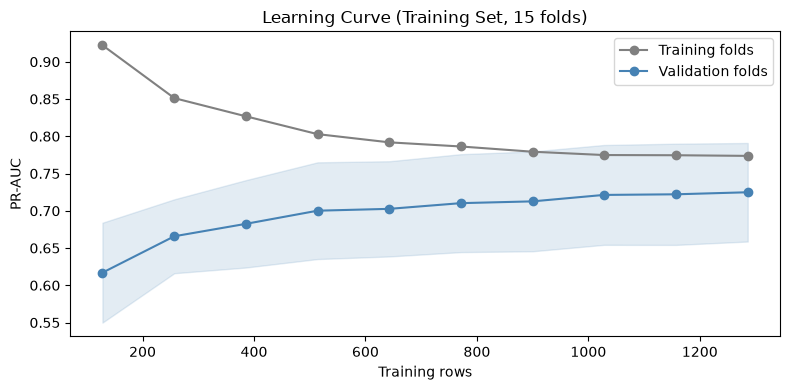


Responders in training: 234 | features: 32 | responders per feature: 7.3
Responders in the test set: 63 of 412


In [17]:
# Is the dataset too small? Learning curve: train on growing shares of each training
# fold and score on the same validation folds. If the validation score is still rising
# steeply at full size, more data would help; if it has levelled off, it would help less.
sizes, train_scores, val_scores = learning_curve(
    LogisticRegression(max_iter=2000), X_all[all_columns], y, cv=cv,
    train_sizes=np.linspace(0.1, 1.0, 10), scoring="average_precision",
    shuffle=True, random_state=42)

curve = pd.DataFrame({"training rows": sizes,
                      "responders (approx.)": (sizes * y.mean()).round().astype(int),
                      "train PR-AUC": train_scores.mean(axis=1).round(3),
                      "validation PR-AUC": val_scores.mean(axis=1).round(3),
                      "validation sd": val_scores.std(axis=1).round(3)})
print(curve.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.plot(sizes, train_scores.mean(axis=1), marker="o", color="grey", label="Training folds")
plt.plot(sizes, val_scores.mean(axis=1), marker="o", color="steelblue", label="Validation folds")
plt.fill_between(sizes, val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1), color="steelblue", alpha=0.15)
plt.xlabel("Training rows"); plt.ylabel("PR-AUC")
plt.title("Learning Curve (Training Set, 15 folds)"); plt.legend()
plt.tight_layout(); plt.show()

# Responders per feature: a common guideline for logistic regression is at least 10
print("\nResponders in training:", int(y.sum()), "| features:", len(all_columns),
      "| responders per feature:", round(y.sum() / len(all_columns), 1))
print("Responders in the test set:", int(test["Response"].sum()), "of", len(test))

### D. Dimensionality reduction
Three approaches, each compared with the full feature set on the same 15 folds:
1. **Aggregation:** replace the five campaign flags with their total (Total_Prev_Accepted).
2. **Correlation filter:** for each pair with |Spearman rho| >= 0.85, drop the weaker feature.
3. **PCA:** replace the features with principal components (refit inside each fold).

In [18]:
# Approach 1: aggregation. Replace the five campaign flags with their total,
# Total_Prev_Accepted (already in the data since Week 4).
aggregated_columns = [c for c in all_columns if c not in campaign_columns]

# Approach 2: correlation filter. For each pair with |Spearman rho| >= 0.85,
# drop the feature with the weaker single-feature signal.
corr = X_all[all_columns].corr(method="spearman").abs()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename("rho").rename_axis(["feature_1", "feature_2"]).reset_index())
strong = pairs[pairs["rho"] >= 0.85].sort_values("rho", ascending=False)
strength = {c: abs(roc_auc_score(y, X_all[c]) - 0.5) for c in all_columns}
filtered_out = set()
for _, row in strong.iterrows():
    a, b = row["feature_1"], row["feature_2"]
    if a not in filtered_out and b not in filtered_out:
        filtered_out.add(a if strength[a] < strength[b] else b)
filtered_columns = [c for c in all_columns if c not in filtered_out]

print("Approach 1 drops:", campaign_columns)
print("\nApproach 2: pairs with |Spearman rho| >= 0.85")
print(strong.round(2).to_string(index=False))
print("Approach 2 drops:", sorted(filtered_out))

Approach 1 drops: ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']

Approach 2: pairs with |Spearman rho| >= 0.85
          feature_1           feature_2  rho
    MntMeatProducts         Total_Spend 0.94
           MntWines         Total_Spend 0.93
        Total_Spend     Total_Purchases 0.90
NumCatalogPurchases         Total_Spend 0.89
  NumStorePurchases     Total_Purchases 0.89
NumCatalogPurchases     Total_Purchases 0.88
           MntWines     Total_Purchases 0.87
             Income         Total_Spend 0.86
             Income   Income_per_Person 0.86
    MntMeatProducts     Total_Purchases 0.86
    MntMeatProducts NumCatalogPurchases 0.85
Approach 2 drops: ['Income', 'MntMeatProducts', 'MntWines', 'NumCatalogPurchases', 'Total_Purchases']


Components for 80% of variance: 8 of 32
Components for 90% of variance: 13 of 32
Components for 95% of variance: 17 of 32


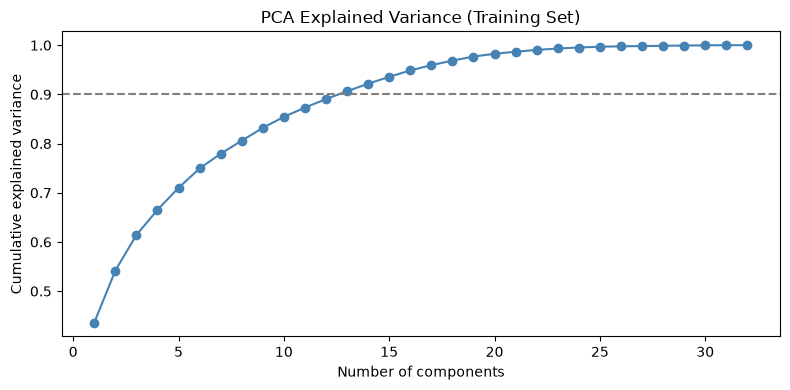

                      setup  features  PR-AUC  PR-AUC sd  ROC-AUC change vs all folds matched or beat (of 15)
               All features        32   0.725      0.066    0.929             -                             -
 1. Campaign flags -> total        27   0.729      0.067    0.930        +0.004                            11
      2. Correlation filter        27   0.711      0.059    0.920        -0.014                             3
3. PCA, 13 components (90%)        13   0.702      0.059    0.915        -0.023                             2
3. PCA, 17 components (95%)        17   0.702      0.063    0.919        -0.023                             1


In [19]:
# Approach 3: PCA. Replace all features with uncorrelated components.
pca = PCA(random_state=42).fit(X_all[all_columns])
cumulative = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.argmax(cumulative >= 0.90) + 1)
n95 = int(np.argmax(cumulative >= 0.95) + 1)
for target in (0.80, 0.90, 0.95):
    print(f"Components for {target:.0%} of variance:", int(np.argmax(cumulative >= target) + 1),
          "of", len(all_columns))

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o", color="steelblue")
plt.axhline(0.90, color="grey", linestyle="--")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA Explained Variance (Training Set)")
plt.tight_layout(); plt.show()

# Compare all approaches on the same folds (PCA is refit inside each fold)
pca_model = lambda n: make_pipeline(PCA(n_components=n, random_state=42),
                                    LogisticRegression(max_iter=2000))
comparison = pd.DataFrame([
    cv_scores(all_columns, "All features"),
    cv_scores(aggregated_columns, "1. Campaign flags -> total"),
    cv_scores(filtered_columns, "2. Correlation filter"),
    cv_scores(all_columns, f"3. PCA, {n90} components (90%)", pca_model(n90), n_features=n90),
    cv_scores(all_columns, f"3. PCA, {n95} components (95%)", pca_model(n95), n_features=n95),
])
comparison["change vs all"] = ["-"] + [f"{vs(s, 'All features')[0]:+.3f}" for s in comparison["setup"][1:]]
comparison["folds matched or beat (of 15)"] = ["-"] + [
    str(int((fold_pr[s] >= fold_pr["All features"]).sum())) for s in comparison["setup"][1:]]
print(comparison.to_string(index=False))

### E. Save model-ready data
Both feature sets are saved for Week 6, with real rows only (no synthetic data).

In [20]:
# Save model-ready data for Week 6 (real rows only; no synthetic data is saved)
# Reduced set = campaign flags replaced by their total (approach 1)
train[all_columns + ["Response"]].to_csv(PROCESSED_DIR / "train_model_full.csv", index=False)
test[all_columns + ["Response"]].to_csv(PROCESSED_DIR / "test_model_full.csv", index=False)
train[aggregated_columns + ["Response"]].to_csv(PROCESSED_DIR / "train_model_reduced.csv", index=False)
test[aggregated_columns + ["Response"]].to_csv(PROCESSED_DIR / "test_model_reduced.csv", index=False)

print("Full set    -> train:", train[all_columns].shape, "| test:", test[all_columns].shape)
print("Reduced set -> train:", train[aggregated_columns].shape, "| test:", test[aggregated_columns].shape)
print("Missing values (train, test):", int(train.isnull().sum().sum()), int(test.isnull().sum().sum()))

Full set    -> train: (1608, 32) | test: (412, 32)
Reduced set -> train: (1608, 27) | test: (412, 27)
Missing values (train, test): 0 0


 Week 5-END

# Week 6- START

In [21]:
# Additional imports for Week 6
import joblib
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_val_predict)

pd.set_option("display.max_colwidth", None)   # show full hyperparameter settings in tables

# Load the model-ready TRAINING data saved in Week 5 (the test files are not loaded)
train_reduced = pd.read_csv(PROCESSED_DIR / "train_model_reduced.csv")
train_full = pd.read_csv(PROCESSED_DIR / "train_model_full.csv")

X = train_reduced.drop(columns="Response")        # 27 features (default set)
X_full = train_full.drop(columns="Response")      # 32 features (for comparison later)
y = train_reduced["Response"]

print("Reduced set:", X.shape, "| Full set:", X_full.shape)
print("Responders:", int(y.sum()), f"({y.mean():.1%})")

Reduced set: (1608, 27) | Full set: (1608, 32)
Responders: 234 (14.6%)


### 6.1 Validation setup
All models use the same 15 folds, so their scores can be compared fold by fold. Both feature sets have the same rows in the same order, so the same folds work for both.

In [22]:
# 5 folds x 3 repeats = 15 train/validation splits (same seed as Week 5)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
splits = list(cv.split(X, y))

# Scores used for tuning
scoring = {"PR-AUC": "average_precision", "ROC-AUC": "roc_auc"}

def evaluate(model, X_data, name):
    """Train the model on each training fold and score it on both the training fold and
    the validation fold. Precision, recall, and F1 use a 0.5 probability cutoff."""
    rows = []
    for fold, (tr, va) in enumerate(splits):
        fitted = clone(model).fit(X_data.iloc[tr], y.iloc[tr])
        for part, idx in (("Training", tr), ("Validation", va)):
            prob = fitted.predict_proba(X_data.iloc[idx])[:, 1]
            true = y.iloc[idx]
            rows.append({"model": name, "fold": fold, "set": part,
                         "PR-AUC": average_precision_score(true, prob),
                         "ROC-AUC": roc_auc_score(true, prob),
                         "Precision": precision_score(true, prob >= 0.5, zero_division=0),
                         "Recall": recall_score(true, prob >= 0.5),
                         "F1": f1_score(true, prob >= 0.5)})
    return pd.DataFrame(rows)

### 6.2 Hyperparameter tuning
Each model is tuned with a grid search over the 15 folds. The best setting is the one with the highest average **validation** PR-AUC. Class weights are included as a tuning option, since Week 5 showed they handle the class imbalance as well as SMOTE.

| Model | Hyperparameters tuned |
|---|---|
| Logistic regression | C (regularization strength), penalty (L1 or L2), class weight |
| Random forest | max depth, min samples per leaf, class weight |
| Gradient boosting | number of trees, learning rate, max depth |

The plots show training and validation PR-AUC as one hyperparameter changes, with the others held at their best values. A large gap between the two lines means the model is memorizing the training folds (overfitting).

In [23]:
def tune(model, grid):
    """Grid search over the 15 folds; picks the setting with the best validation PR-AUC."""
    search = GridSearchCV(model, grid, scoring=scoring, refit="PR-AUC",
                          cv=splits, n_jobs=-1, return_train_score=True)
    return search.fit(X, y)

def top_results(search, n=5):
    """Top n settings ranked by validation PR-AUC."""
    r = pd.DataFrame(search.cv_results_).sort_values("rank_test_PR-AUC").head(n)
    return pd.DataFrame({"settings": r["params"],
                         "train PR-AUC": r["mean_train_PR-AUC"].round(3),
                         "validation PR-AUC": r["mean_test_PR-AUC"].round(3),
                         "validation sd": r["std_test_PR-AUC"].round(3),
                         "validation ROC-AUC": r["mean_test_ROC-AUC"].round(3)}).reset_index(drop=True)

def plot_param(search, grid, param, title):
    """Train vs validation PR-AUC as one hyperparameter changes (others at their best values)."""
    r = pd.DataFrame(search.cv_results_)
    others = {k: v for k, v in search.best_params_.items() if k != param}
    train_scores, val_scores = [], []
    for value in grid[param]:
        row = r[r["params"].apply(lambda p: p == {**others, param: value})]
        train_scores.append(row["mean_train_PR-AUC"].iloc[0])
        val_scores.append(row["mean_test_PR-AUC"].iloc[0])
    positions = range(len(grid[param]))
    plt.figure(figsize=(7, 3.5))
    plt.plot(positions, train_scores, marker="o", color="grey", label="Training folds")
    plt.plot(positions, val_scores, marker="o", color="steelblue", label="Validation folds")
    plt.xticks(positions, [str(v) for v in grid[param]])
    plt.xlabel(param); plt.ylabel("PR-AUC"); plt.title(title); plt.legend()
    plt.tight_layout(); plt.show()

/Users/nathanmyang/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/nathanmyang/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/nathanmyang/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use

Best settings: {'C': 3, 'class_weight': None, 'penalty': 'l2'}
                                           settings  train PR-AUC  validation PR-AUC  validation sd  validation ROC-AUC
0   {'C': 3, 'class_weight': None, 'penalty': 'l2'}         0.772              0.732          0.065               0.930
1   {'C': 3, 'class_weight': None, 'penalty': 'l1'}         0.774              0.731          0.066               0.929
2  {'C': 10, 'class_weight': None, 'penalty': 'l2'}         0.774              0.731          0.063               0.929
3  {'C': 10, 'class_weight': None, 'penalty': 'l1'}         0.774              0.730          0.062               0.929
4   {'C': 1, 'class_weight': None, 'penalty': 'l2'}         0.767              0.728          0.068               0.929


/Users/nathanmyang/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/nathanmyang/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/nathanmyang/miniconda

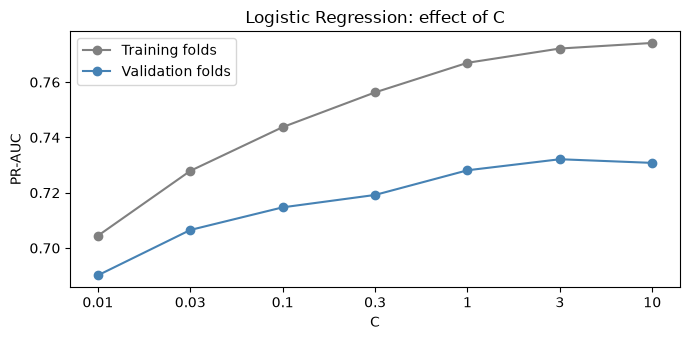

In [24]:

# Model 1: logistic regression. Weeks 4-5 used it with default settings to compare
# data choices; here we tune its settings to get the best version of it.
lr_grid = {"C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],     # smaller C = stronger regularization
           "penalty": ["l1", "l2"],                    # L1 can shrink weak features to zero
           "class_weight": [None, "balanced"]}
lr_search = tune(LogisticRegression(solver="liblinear", max_iter=5000), lr_grid)

print("Best settings:", lr_search.best_params_)
print(top_results(lr_search).to_string())
plot_param(lr_search, lr_grid, "C", "Logistic Regression: effect of C")

Best settings: {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 5}
                                                                            settings  train PR-AUC  validation PR-AUC  validation sd  validation ROC-AUC
0                   {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 5}         0.968              0.650          0.063               0.900
1      {'class_weight': 'balanced_subsample', 'max_depth': 8, 'min_samples_leaf': 5}         0.972              0.650          0.060               0.902
2   {'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_leaf': 5}         0.984              0.648          0.061               0.902
3                      {'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 5}         0.938              0.642          0.067               0.896
4  {'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_leaf': 10}         0.913              0.638          0.061               0.899


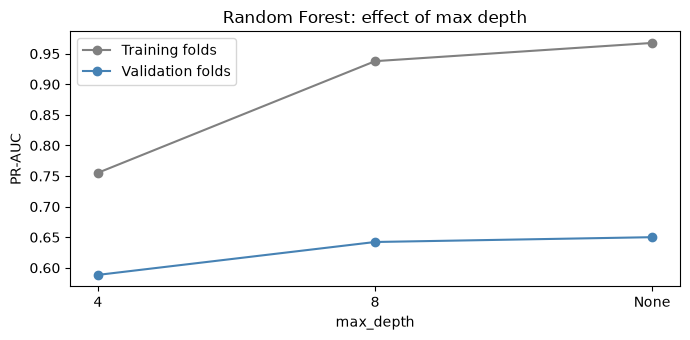

In [25]:
# Model 2: random forest (many decision trees, each on a random sample of rows and features)
rf_grid = {"max_depth": [4, 8, None],                   # None = trees grow until leaves are pure
           "min_samples_leaf": [5, 10],                 # larger leaves = smoother, less overfit
           "class_weight": [None, "balanced_subsample"]}
rf_search = tune(RandomForestClassifier(n_estimators=200, max_features="sqrt",
                                        random_state=42, n_jobs=1), rf_grid)

print("Best settings:", rf_search.best_params_)
print(top_results(rf_search).to_string())
plot_param(rf_search, rf_grid, "max_depth", "Random Forest: effect of max depth")

Best settings: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200}
                                                       settings  train PR-AUC  validation PR-AUC  validation sd  validation ROC-AUC
0  {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200}         0.885              0.693          0.057               0.910
1   {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}         0.885              0.690          0.058               0.910
2   {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}         0.951              0.689          0.064               0.912
3  {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}         0.977              0.687          0.056               0.914
4  {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}         0.916              0.682          0.052               0.905


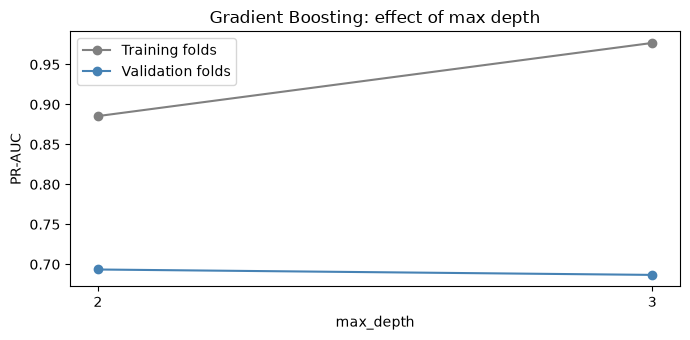

In [26]:
# Model 3: gradient boosting (trees built one after another, each fixing the last one's errors)
gb_grid = {"n_estimators": [100, 200],                  # number of trees
           "learning_rate": [0.05, 0.1],                # how much each tree contributes
           "max_depth": [2, 3]}                         # depth of each tree
gb_search = tune(GradientBoostingClassifier(subsample=0.8, random_state=42), gb_grid)

print("Best settings:", gb_search.best_params_)
print(top_results(gb_search).to_string())
plot_param(gb_search, gb_grid, "max_depth", "Gradient Boosting: effect of max depth")

### 6.3 Model performance metrics: training vs validation
Each tuned model is compared with two baselines:
- **Default logistic regression:** the same untuned model used in Weeks 4–5 to compare data choices. It shows how much tuning and stronger models add.
- **Prior-campaign rule:** rank customers by how many earlier campaigns they accepted. Week 3 showed this simple rule is the real bar to beat, not the 15% base rate.

PR-AUC and ROC-AUC measure how well a model ranks responders above non-responders. Precision, recall, and F1 use a 0.5 cutoff: precision is the share of contacted customers who respond, and recall is the share of all responders we reach. Models with class weights push probabilities up, so they trade precision for recall at the same cutoff.

In [27]:
models = {
    "Logistic regression (default)": LogisticRegression(max_iter=2000),
    "Logistic regression (tuned)": lr_search.best_estimator_,
    "Random forest (tuned)": rf_search.best_estimator_,
    "Gradient boosting (tuned)": gb_search.best_estimator_,
}
results = pd.concat([evaluate(m, X, name) for name, m in models.items()], ignore_index=True)

# Average of the 15 folds, training and validation side by side
metrics = ["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1"]
summary = results.groupby(["model", "set"], sort=False)[metrics].mean().round(3)
print(summary.to_string())

# Baseline: prior-campaign rule, scored on the same validation folds (no training needed)
rule_pr = [average_precision_score(y.iloc[va], X["Total_Prev_Accepted"].iloc[va]) for _, va in splits]
print(f"\nPrior-campaign rule, validation PR-AUC: {np.mean(rule_pr):.3f}")
print(f"Random guessing, validation PR-AUC: {y.mean():.3f}")

/Users/nathanmyang/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/nathanmyang/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/nathanmyang/miniconda

                                          PR-AUC  ROC-AUC  Precision  Recall     F1
model                         set                                                  
Logistic regression (default) Training     0.769    0.941      0.789   0.565  0.658
                              Validation   0.729    0.930      0.743   0.547  0.627
Logistic regression (tuned)   Training     0.772    0.941      0.784   0.576  0.664
                              Validation   0.732    0.930      0.740   0.558  0.633
Random forest (tuned)         Training     0.968    0.994      0.987   0.574  0.725
                              Validation   0.650    0.900      0.828   0.257  0.390
Gradient boosting (tuned)     Training     0.885    0.969      0.935   0.613  0.740
                              Validation   0.693    0.910      0.784   0.439  0.558

Prior-campaign rule, validation PR-AUC: 0.395
Random guessing, validation PR-AUC: 0.146


                               train PR-AUC  validation PR-AUC  validation sd  gap (train - validation)  folds beating default LR (of 15)
model                                                                                                                                    
Logistic regression (default)         0.769              0.729          0.070                     0.040                               NaN
Logistic regression (tuned)           0.772              0.732          0.068                     0.040                               9.0
Random forest (tuned)                 0.968              0.650          0.066                     0.317                               1.0
Gradient boosting (tuned)             0.885              0.693          0.059                     0.192                               3.0


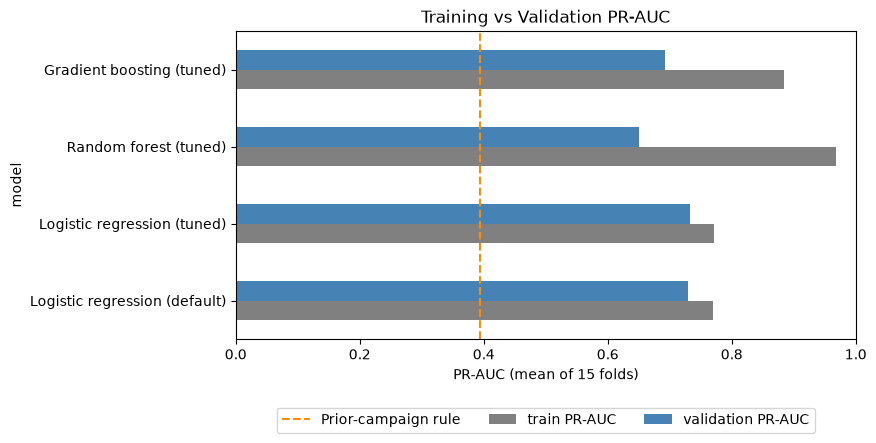

In [28]:
# Overfitting check and fold-by-fold comparison with the default logistic regression
val = results[results["set"] == "Validation"].pivot(index="fold", columns="model", values="PR-AUC")
train = results[results["set"] == "Training"].pivot(index="fold", columns="model", values="PR-AUC")
baseline = "Logistic regression (default)"

comparison = pd.DataFrame({
    "train PR-AUC": train.mean(),
    "validation PR-AUC": val.mean(),
    "validation sd": val.std(),
    "gap (train - validation)": train.mean() - val.mean(),
    "folds beating default LR (of 15)": (val.gt(val[baseline], axis=0)).sum(),
}).loc[list(models)].round(3)
comparison.loc[baseline, "folds beating default LR (of 15)"] = np.nan
print(comparison.to_string())

# Chart: training vs validation PR-AUC for each model
ax = comparison[["train PR-AUC", "validation PR-AUC"]].plot.barh(
    figsize=(8, 4), color=["grey", "steelblue"])
ax.axvline(np.mean(rule_pr), color="darkorange", linestyle="--", label="Prior-campaign rule")
ax.set_xlabel("PR-AUC (mean of 15 folds)"); ax.set_xlim(0, 1)
ax.set_title("Training vs Validation PR-AUC")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)

### 6.4 Precision-recall curves (validation predictions)
Each customer gets a probability from a model that didn't see them during training (5-fold cross-validated predictions). The curve shows the precision we'd get at every level of recall. The higher and further right the curve, the better.

/Users/nathanmyang/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/nathanmyang/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/nathanmyang/miniconda

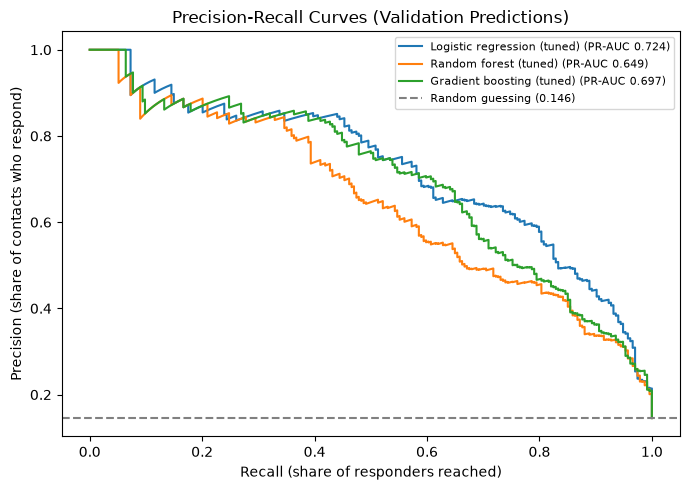

In [29]:
# Cross-validated probabilities: each customer is scored by a model trained without them
oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_prob = {name: cross_val_predict(m, X, y, cv=oof_cv, method="predict_proba")[:, 1]
            for name, m in models.items() if name != baseline}

plt.figure(figsize=(7, 5))
for name, prob in oof_prob.items():
    precision, recall, _ = precision_recall_curve(y, prob)
    plt.plot(recall, precision, label=f"{name} (PR-AUC {average_precision_score(y, prob):.3f})")
plt.axhline(y.mean(), color="grey", linestyle="--", label=f"Random guessing ({y.mean():.3f})")
plt.xlabel("Recall (share of responders reached)"); plt.ylabel("Precision (share of contacts who respond)")
plt.title("Precision-Recall Curves (Validation Predictions)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 6.5 Best model: feature set check and cutoff
We take the model with the highest validation PR-AUC and do two things:
1. **Check the feature set.** Week 5 chose the 27-feature reduced set using a simple logistic regression. We test the best model on both the reduced and the full 32-feature set to confirm that choice still holds.
2. **Choose a cutoff.** The model gives each customer a probability of responding. We contact customers above a cutoff, choosing the cutoff that best balances reaching responders (recall) against wasting contacts (precision), measured by F1. The confusion matrix shows how many responders are caught or missed at that cutoff. The cutoff will be checked once on the test set in the final evaluation.

In [30]:
# Best model by mean validation PR-AUC (baselines excluded)
best_name = comparison.drop(index=baseline)["validation PR-AUC"].idxmax()
best_model = models[best_name]
print("Best model:", best_name)

# 1. Reduced (27) vs full (32) feature set, same folds
full_results = evaluate(best_model, X_full, best_name + " - full set")
val_reduced = results[(results["model"] == best_name) & (results["set"] == "Validation")]["PR-AUC"].to_numpy()
val_full = full_results[full_results["set"] == "Validation"]["PR-AUC"].to_numpy()
print(f"\nValidation PR-AUC  reduced set (27): {val_reduced.mean():.3f}"
      f" | full set (32): {val_full.mean():.3f}"
      f" | reduced matched or beat full on {(val_reduced >= val_full).sum()} of 15 folds")

Best model: Logistic regression (tuned)


/Users/nathanmyang/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/nathanmyang/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/nathanmyang/miniconda


Validation PR-AUC  reduced set (27): 0.732 | full set (32): 0.727 | reduced matched or beat full on 9 of 15 folds


/Users/nathanmyang/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/nathanmyang/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/nathanmyang/miniconda

In [31]:
# 2. Cutoff that maximizes F1 on the validation predictions
prob = oof_prob[best_name]
precision, recall, thresholds = precision_recall_curve(y, prob)
f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
best_cut = thresholds[np.argmax(f1)]

predicted = (prob >= best_cut).astype(int)
print(f"Chosen cutoff: {best_cut:.2f}")
print(f"Precision: {precision_score(y, predicted):.3f} | Recall: {recall_score(y, predicted):.3f}"
      f" | F1: {f1_score(y, predicted):.3f}")
print(f"Customers flagged to contact: {predicted.sum()} of {len(y)} ({predicted.mean():.1%})")

print("\nConfusion matrix (validation predictions):")
print(pd.DataFrame(confusion_matrix(y, predicted),
                   index=["Actual: no response", "Actual: response"],
                   columns=["Predicted: no response", "Predicted: response"]))

Chosen cutoff: 0.29
Precision: 0.637 | Recall: 0.735 | F1: 0.683
Customers flagged to contact: 270 of 1608 (16.8%)

Confusion matrix (validation predictions):
                     Predicted: no response  Predicted: response
Actual: no response                    1276                   98
Actual: response                         62                  172


In [32]:
# Save the best model, trained on the full training set (reduced features), for later weeks
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
final_model = clone(best_model).fit(X, y)
joblib.dump({"model": final_model, "features": list(X.columns), "cutoff": float(best_cut)},
            MODEL_DIR / "week6_best_model.joblib")
print("Saved:", MODEL_DIR / "week6_best_model.joblib")

Saved: ../models/week6_best_model.joblib


/Users/nathanmyang/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


### 6.6 Summary

**Best model: tuned logistic regression** ([best settings from 6.2, e.g. C = 0.1, L2 penalty, no class weights]).

**Performance (validation predictions, PR-AUC):**
| Model | PR-AUC |
|---|---|
| Logistic regression (tuned) | 0.724 |
| Gradient boosting (tuned) | 0.695 |
| Random forest (tuned) | 0.649 |
| Prior-campaign rule | ~0.40 |
| Random guessing | 0.146 |

All three models beat the prior-campaign rule by a wide margin. Logistic regression's precision-recall curve stays above the others across most recall levels, especially from 60% to 90% recall, the range that matters for choosing who to contact.

**Training vs validation (overfitting check):** the tree models scored much higher on training folds than on validation folds. Random forest dropped from about 0.97 to 0.65 and gradient boosting from about 0.88 to 0.69, which means they memorized the training customers. Logistic regression had a small gap (about 0.77 vs 0.73), so its patterns hold for customers it hasn't seen. With only 234 responders, the simpler model generalizes better.

**Effect of tuning:** tuned logistic regression scored [X] validation PR-AUC vs [Y] for the default settings, beating it on [N] of 15 folds. [If the difference is 0.01 or less: Tuning added little; the gain comes from logistic regression suiting this data rather than from the tuning itself.]

**Feature set:** the reduced 27-feature set scored [X] vs [Y] for the full 32-feature set, matching or beating it on [N] of 15 folds, [confirming / not confirming] the Week 5 choice.

**Cutoff:** a 0.29 cutoff maximizes F1. At that cutoff the model contacts 270 of 1,608 customers (16.8%) and reaches 172 of the 234 responders (recall 0.735). About 64% of contacted customers respond (precision 0.637), compared with 14.6% if everyone were contacted. It misses 62 responders and contacts 98 non-responders. The cutoff is below 0.5 because only 15% of customers respond, so predicted probabilities rarely run high.



# Week 6-END

# Week 7- START
## More complex model: neural network (MLP)

This week we move from Week 6's models to a **multilayer perceptron (MLP) neural network**, the most flexible model so far, and evaluate **3 variations** of it. Each variation changes its hyperparameters. Every model is scored on the same 15 training/validation splits as Week 6, and the test set stays untouched.

| Section | What it does |
|---|---|
| 7.0 | Setup: load data, same 15 folds, evaluation helper |
| 7.1 | Does the order of the earlier campaigns help? (professor's sequential-data suggestion) |
| 7.2 | Modeling approach, complexity, and hyperparameters |
| 7.3 to 7.5 | The three variations, each scored on training and validation folds |
| 7.6 | Evaluation: metrics table, overfitting check, charts |
| 7.7 | Best model of the week |

### 7.0 Setup
We reload the model-ready training data saved in Week 5, so this section runs on its own. The test files are not loaded. The 15 folds (5 folds x 3 repeats, seed 42) are the same as in Week 6, and the metrics are the same too, so Week 7 results can be compared directly with Week 6.

In [33]:
# Additional imports for Week 7
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# MLPClassifier warns when it stops at max_iter before the loss has fully settled.
# That is expected for the larger networks, so we hide the warning to keep the output readable.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

# Model-ready TRAINING data from Week 5 (same rows, same order in both files)
PROCESSED_DIR = Path("../data/processed")
full7 = pd.read_csv(PROCESSED_DIR / "train_model_full.csv")        # 32 features (includes the 5 campaign flags)
reduced7 = pd.read_csv(PROCESSED_DIR / "train_model_reduced.csv")  # 27 features (flags replaced by their total)
assert (full7["Response"].to_numpy() == reduced7["Response"].to_numpy()).all()

X7 = reduced7.drop(columns="Response")
y7 = reduced7["Response"]
print("Features:", X7.shape[1], "| Customers:", len(X7), "| Responders:", int(y7.sum()), f"({y7.mean():.1%})")

# Same 15 train/validation splits as Week 6 (5 folds x 3 repeats, seed 42)
splits7 = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42).split(X7, y7))
metrics7 = ["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1"]

def evaluate7(model, X_data, name):
    """Train on each of the 15 training folds and score on both the training fold and the
    validation fold. Precision, recall, and F1 use a 0.5 probability cutoff (same as Week 6)."""
    rows = []
    for fold, (tr, va) in enumerate(splits7):
        fitted = clone(model).fit(X_data.iloc[tr], y7.iloc[tr])
        for part, idx in (("Training", tr), ("Validation", va)):
            prob = fitted.predict_proba(X_data.iloc[idx])[:, 1]
            true = y7.iloc[idx]
            rows.append({"model": name, "fold": fold, "set": part,
                         "PR-AUC": average_precision_score(true, prob),
                         "ROC-AUC": roc_auc_score(true, prob),
                         "Precision": precision_score(true, prob >= 0.5, zero_division=0),
                         "Recall": recall_score(true, prob >= 0.5),
                         "F1": f1_score(true, prob >= 0.5)})
    return pd.DataFrame(rows)

Features: 27 | Customers: 1608 | Responders: 234 (14.6%)


### 7.1 Does the order of the earlier campaigns help?
Our professor suggested a model for sequential data, which would read AcceptedCmp1 to AcceptedCmp5 in order and learn from the pattern in which a customer responded. Before building one, we checked whether that fits our data:

- **We cannot confirm the order.** The columns are numbered 1 to 5, but the dataset has no campaign dates, so we don't know they are in time order (Week 2 noted the same for the last campaign).
- **A 0 is ambiguous.** It can mean the customer declined, or that they were never contacted or had not yet become a customer. The data cannot tell these apart, so a "pattern" of 0s and 1s is partly a pattern of who was contacted.
- **The sequence is very short.** Each customer has five 0/1 values, so there are only 32 possible histories, and the tables below show how many customers share the same one. That is little for a recurrent network to learn from with 234 responders.
- **Week 5 pointed the same way.** Replacing the five flags with their total did not hurt performance (+0.004).

So instead of building a sequence model, we test the idea directly. We add three features that capture order (most recent campaign accepted, accepted in the last two campaigns, accepted in the first two) and check whether they improve PR-AUC on the same 15 folds. If they do, they are added to the neural network's inputs. We use the simple logistic regression yardstick from Week 5.

In [34]:
# What does the campaign history look like?
campaign_cols = [f"AcceptedCmp{i}" for i in range(1, 6)]
flags = full7[campaign_cols].astype(int)
n_accepted = flags.sum(axis=1)

print("Acceptance rate by campaign (Response is the last campaign, shown for comparison):")
by_campaign = pd.DataFrame({"customers who accepted": flags.sum(),
                            "acceptance rate": flags.mean().round(3),
                            "Response rate among them": [round(y7[flags[c] == 1].mean(), 3) for c in campaign_cols]})
by_campaign.loc["Response (last campaign)"] = [int(y7.sum()), round(y7.mean(), 3), np.nan]
print(by_campaign.to_string())

print("\nCustomers by number of earlier campaigns accepted:")
by_count = pd.DataFrame({"customers": n_accepted.value_counts().sort_index(),
                         "share of customers": (n_accepted.value_counts(normalize=True).sort_index() * 100).round(1),
                         "Response rate (%)": (y7.groupby(n_accepted).mean() * 100).round(1)})
print(by_count.to_string())

Acceptance rate by campaign (Response is the last campaign, shown for comparison):
                          customers who accepted  acceptance rate  Response rate among them
AcceptedCmp1                               113.0            0.070                     0.558
AcceptedCmp2                                21.0            0.013                     0.762
AcceptedCmp3                               117.0            0.073                     0.487
AcceptedCmp4                               124.0            0.077                     0.355
AcceptedCmp5                               120.0            0.075                     0.533
Response (last campaign)                   234.0            0.146                       NaN

Customers by number of earlier campaigns accepted:
   customers  share of customers  Response rate (%)
0       1270                79.0                7.6
1        233                14.5               30.9
2         62                 3.9               50.0
3         34 

In [35]:
# Does ORDER matter beyond the count? Compare customers who accepted exactly ONE earlier campaign,
# split by which campaign it was. If later campaigns were more informative, their response rate
# would be higher. (Small groups, so differences of a few points are noise.)
one = n_accepted == 1
which = flags[one].idxmax(axis=1)
print("Customers who accepted exactly one earlier campaign, by which one:")
print(pd.DataFrame({"customers": which.value_counts().sort_index(),
                    "Response rate (%)": (y7[one].groupby(which).mean() * 100).round(1)}).to_string())

# Most common full histories (1 = accepted)
pattern = flags.astype(str).agg("".join, axis=1)
print("\nMost common campaign histories (campaigns 1 to 5):")
print(pd.DataFrame({"customers": pattern.value_counts(),
                    "Response rate (%)": (y7.groupby(pattern).mean() * 100).round(1)})
      .loc[pattern.value_counts().index].head(10).to_string())

Customers who accepted exactly one earlier campaign, by which one:
              customers  Response rate (%)
AcceptedCmp1         38               26.3
AcceptedCmp2          1              100.0
AcceptedCmp3         92               42.4
AcceptedCmp4         62               12.9
AcceptedCmp5         40               35.0

Most common campaign histories (campaigns 1 to 5):
       customers  Response rate (%)
00000       1270                7.6
00100         92               42.4
00010         62               12.9
00001         40               35.0
10000         38               26.3
10001         18               61.1
10011         18               77.8
00011         17               29.4
10010         12               50.0
10101         11               72.7


In [36]:
# Do order features improve predictions? Same 15 folds, simple logistic regression as the yardstick.
def sequence_features(f):
    return pd.DataFrame({
        "Last_Accepted_Campaign": (f.to_numpy() * np.arange(1, 6)).max(axis=1),   # 0 = never accepted
        "Accepted_Campaigns_4_5": f["AcceptedCmp4"] + f["AcceptedCmp5"],          # most recent two
        "Accepted_Campaigns_1_2": f["AcceptedCmp1"] + f["AcceptedCmp2"],          # earliest two
    }, index=f.index)

seq_feats = sequence_features(flags)

def lr_fold_scores(X_data):
    return np.array([average_precision_score(
        y7.iloc[va],
        LogisticRegression(max_iter=2000).fit(X_data.iloc[tr], y7.iloc[tr]).predict_proba(X_data.iloc[va])[:, 1])
        for tr, va in splits7])

setups = {"Count of campaigns accepted only (27 features)": X7,
          "+ order features (30 features)": pd.concat([X7, seq_feats], axis=1),
          "All five flags separately (32 features)": full7.drop(columns="Response")}
fold_scores = {name: lr_fold_scores(data) for name, data in setups.items()}
base = fold_scores["Count of campaigns accepted only (27 features)"]

order_test = pd.DataFrame({
    "PR-AUC": {n: s.mean() for n, s in fold_scores.items()},
    "PR-AUC sd": {n: s.std() for n, s in fold_scores.items()},
    "change vs count only": {n: (s - base).mean() for n, s in fold_scores.items()},
    "folds improved (of 15)": {n: int((s > base).sum()) for n, s in fold_scores.items()}}).round(3)
order_test.loc["Count of campaigns accepted only (27 features)", ["change vs count only", "folds improved (of 15)"]] = np.nan
print(order_test.to_string())

# Decision rule: keep the order features only if they clearly help (+0.005 or more AND better on 10+ of 15 folds)
gain = (fold_scores["+ order features (30 features)"] - base)
use_sequence = bool(gain.mean() >= 0.005 and (gain > 0).sum() >= 10)
X_model = pd.concat([X7, seq_feats], axis=1) if use_sequence else X7
print(f"\nChange in PR-AUC from order features: {gain.mean():+.3f}, better on {(gain > 0).sum()} of 15 folds")
print("Decision:", "add the order features to the neural network" if use_sequence else
      "do not add them; the count of campaigns accepted already carries the signal")
print("Neural network input features:", X_model.shape[1])

                                                PR-AUC  PR-AUC sd  change vs count only  folds improved (of 15)
Count of campaigns accepted only (27 features)   0.729      0.067                   NaN                     NaN
+ order features (30 features)                   0.730      0.068                 0.001                     9.0
All five flags separately (32 features)          0.725      0.066                -0.004                     4.0

Change in PR-AUC from order features: +0.001, better on 9 of 15 folds
Decision: do not add them; the count of campaigns accepted already carries the signal
Neural network input features: 27


### 7.2 Modeling approach: neural network (MLP)
An MLP passes the features through one or more hidden layers. Each hidden unit takes a weighted sum of its inputs and applies a non-linear function (ReLU), so the network can learn interactions that logistic regression cannot. One example is the household effect from Week 3, where single customers with no children respond far more than either factor alone would suggest.

**Why this approach:** it is the natural step up in complexity from Week 6, and it is the same family as the recurrent networks used for sequential data. Section 7.1 shows that our campaign history is too short and too ambiguous to justify a sequence model, so we use a standard MLP on the customer features.

**Complexity:** logistic regression learns one weight per feature (about 30 numbers). An MLP learns a weight for every connection between layers, so even a small network has hundreds of weights and a larger one has thousands (counted below). With only 234 responders, the risk is the same as in Week 6: a flexible model can memorize the training customers. The three variations are designed to show how network size and regularization control that.

**Hyperparameters:**

| Hyperparameter | What it controls | Variation 1 | Variation 2 | Variation 3 |
|---|---|---|---|---|
| `hidden_layer_sizes` | Network size: how much it can memorize | (8,) | (16,) | (64, 32) |
| `alpha` | L2 penalty on large weights: higher = simpler, smoother model | 3.0 | 1.0 | 0.001 |

We vary these two because they are the settings that most directly control overfitting in a small-data neural network, and they move together as a complexity dial: Variation 1 is small and strongly regularized, Variation 3 is large and lightly regularized. All other settings are held fixed: ReLU activation, the Adam optimizer, learning rate 0.001, up to 500 training passes, and a standard scaler fit inside each training fold so the validation fold never influences the scaling.

In [37]:
# The three variations. Only hidden_layer_sizes and alpha change.
def make_mlp(hidden, alpha):
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, activation="relu", solver="adam",
                      learning_rate_init=0.001, max_iter=500, random_state=42))

variations = {"Variation 1": make_mlp((8,), 3.0),
              "Variation 2": make_mlp((16,), 1.0),
              "Variation 3": make_mlp((64, 32), 0.001)}
reference_name = "Logistic regression (default)"   # same untuned model used in Weeks 4-6
res7 = {}                                          # training and validation scores for every model

# Count the weights each network learns (fit once on all training rows, just to count)
def n_weights(pipe):
    mlp = pipe.named_steps["mlpclassifier"]
    return sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)

settings = pd.DataFrame({
    name: {"hidden layers": str(p.named_steps["mlpclassifier"].hidden_layer_sizes),
           "alpha": p.named_steps["mlpclassifier"].alpha,
           "weights learned": n_weights(clone(p).fit(X_model, y7))}
    for name, p in variations.items()}).T
settings.loc[reference_name] = ["-", "-", X_model.shape[1] + 1]
print(settings.to_string())

def show_variation(name):
    """Average of the 15 folds, training vs validation, for one model."""
    r = res7[name]
    table = r.groupby("set")[metrics7].mean().loc[["Training", "Validation"]].round(3)
    print(table.to_string())
    gap = table.loc["Training", "PR-AUC"] - table.loc["Validation", "PR-AUC"]
    sd = r[r["set"] == "Validation"]["PR-AUC"].std()
    print(f"\nPR-AUC gap (training - validation): {gap:.3f} | validation PR-AUC sd across folds: {sd:.3f}")

                              hidden layers  alpha weights learned
Variation 1                            (8,)    3.0             233
Variation 2                           (16,)    1.0             465
Variation 3                        (64, 32)  0.001            3905
Logistic regression (default)             -      -              28


### 7.3 Variation 1: small network, strong regularization
One hidden layer of 8 units with a strong L2 penalty (`alpha` = 3.0). This is the simplest network, closest to logistic regression in how much it can learn.

In [38]:
res7["Variation 1"] = evaluate7(variations["Variation 1"], X_model, "Variation 1")
show_variation("Variation 1")

            PR-AUC  ROC-AUC  Precision  Recall     F1
set                                                  
Training     0.779    0.943      0.832   0.527  0.645
Validation   0.725    0.928      0.780   0.486  0.596

PR-AUC gap (training - validation): 0.054 | validation PR-AUC sd across folds: 0.061


### 7.4 Variation 2: medium network, moderate regularization
One hidden layer of 16 units with a moderate penalty (`alpha` = 1.0). Twice the units of Variation 1 and a weaker penalty: more capacity to learn interactions, with some protection against memorizing.

In [39]:
res7["Variation 2"] = evaluate7(variations["Variation 2"], X_model, "Variation 2")
show_variation("Variation 2")

            PR-AUC  ROC-AUC  Precision  Recall     F1
set                                                  
Training     0.867    0.968      0.867   0.654  0.745
Validation   0.722    0.927      0.750   0.551  0.632

PR-AUC gap (training - validation): 0.145 | validation PR-AUC sd across folds: 0.053


### 7.5 Variation 3: large network, light regularization
Two hidden layers (64 and 32 units) with a very light penalty (`alpha` = 0.001). The most flexible version, and the one most likely to memorize the training folds.

In [40]:
res7["Variation 3"] = evaluate7(variations["Variation 3"], X_model, "Variation 3")
show_variation("Variation 3")

            PR-AUC  ROC-AUC  Precision  Recall     F1
set                                                  
Training     1.000    1.000      1.000   1.000  1.000
Validation   0.678    0.914      0.673   0.585  0.623

PR-AUC gap (training - validation): 0.322 | validation PR-AUC sd across folds: 0.059


### 7.6 Evaluation: training vs validation
**Metrics.** PR-AUC is the main metric, as in Week 6: only 14.6% of customers respond, so accuracy is misleading, and PR-AUC measures how well a model ranks the likely responders first, which is how the model would be used to choose who to contact. ROC-AUC is secondary. Precision, recall, and F1 use a 0.5 cutoff, so a model with low recall at 0.5 may still rank well; Week 6 chose a better cutoff for the final model.

All values are averages over the 15 folds. Two reference points are scored the same way: the default logistic regression from Week 6 (an untuned simple model on the same features) and the prior-campaign rule (rank customers by how many earlier campaigns they accepted).

In [41]:
# Reference: the untuned logistic regression from Weeks 4-6, on the same features and folds
res7[reference_name] = evaluate7(LogisticRegression(max_iter=2000), X_model, reference_name)

all_results = pd.concat(res7.values(), ignore_index=True)
order = list(variations) + [reference_name]

# Table: 3 variations, training and validation values for every metric (mean of 15 folds)
summary7 = all_results.groupby(["model", "set"], sort=False)[metrics7].mean().round(3).loc[order]
print(summary7.to_string())

# Baselines on the same validation folds
rule_pr = [average_precision_score(y7.iloc[va], X7["Total_Prev_Accepted"].iloc[va]) for _, va in splits7]
print(f"\nPrior-campaign rule, validation PR-AUC: {np.mean(rule_pr):.3f}")
print(f"Random guessing, validation PR-AUC: {y7.mean():.3f}")

                                          PR-AUC  ROC-AUC  Precision  Recall     F1
model                         set                                                  
Variation 1                   Training     0.779    0.943      0.832   0.527  0.645
                              Validation   0.725    0.928      0.780   0.486  0.596
Variation 2                   Training     0.867    0.968      0.867   0.654  0.745
                              Validation   0.722    0.927      0.750   0.551  0.632
Variation 3                   Training     1.000    1.000      1.000   1.000  1.000
                              Validation   0.678    0.914      0.673   0.585  0.623
Logistic regression (default) Training     0.769    0.941      0.789   0.565  0.658
                              Validation   0.729    0.930      0.743   0.547  0.627

Prior-campaign rule, validation PR-AUC: 0.395
Random guessing, validation PR-AUC: 0.146


                               train PR-AUC  validation PR-AUC  validation sd  gap (train - validation)  folds beating default LR (of 15)
model                                                                                                                                    
Variation 1                           0.779              0.725          0.061                     0.054                               6.0
Variation 2                           0.867              0.722          0.053                     0.145                               8.0
Variation 3                           1.000              0.678          0.059                     0.322                               3.0
Logistic regression (default)         0.769              0.729          0.070                     0.040                               NaN


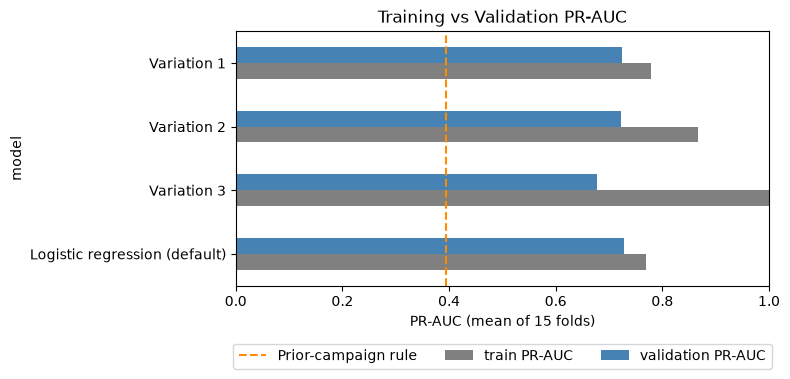

In [42]:
# Overfitting check: gap between training and validation PR-AUC, and fold-by-fold comparison
val7 = all_results[all_results["set"] == "Validation"].pivot(index="fold", columns="model", values="PR-AUC")
trn7 = all_results[all_results["set"] == "Training"].pivot(index="fold", columns="model", values="PR-AUC")

comparison7 = pd.DataFrame({
    "train PR-AUC": trn7.mean(),
    "validation PR-AUC": val7.mean(),
    "validation sd": val7.std(),
    "gap (train - validation)": trn7.mean() - val7.mean(),
    "folds beating default LR (of 15)": val7.gt(val7[reference_name], axis=0).sum(),
}).loc[order].round(3)
comparison7.loc[reference_name, "folds beating default LR (of 15)"] = np.nan
print(comparison7.to_string())

# Chart: training vs validation PR-AUC for each model
ax = comparison7[["train PR-AUC", "validation PR-AUC"]].iloc[::-1].plot.barh(
    figsize=(8, 4), color=["grey", "steelblue"])
ax.axvline(np.mean(rule_pr), color="darkorange", linestyle="--", label="Prior-campaign rule")
ax.set_xlabel("PR-AUC (mean of 15 folds)"); ax.set_xlim(0, 1)
ax.set_title("Training vs Validation PR-AUC")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout(); plt.show()

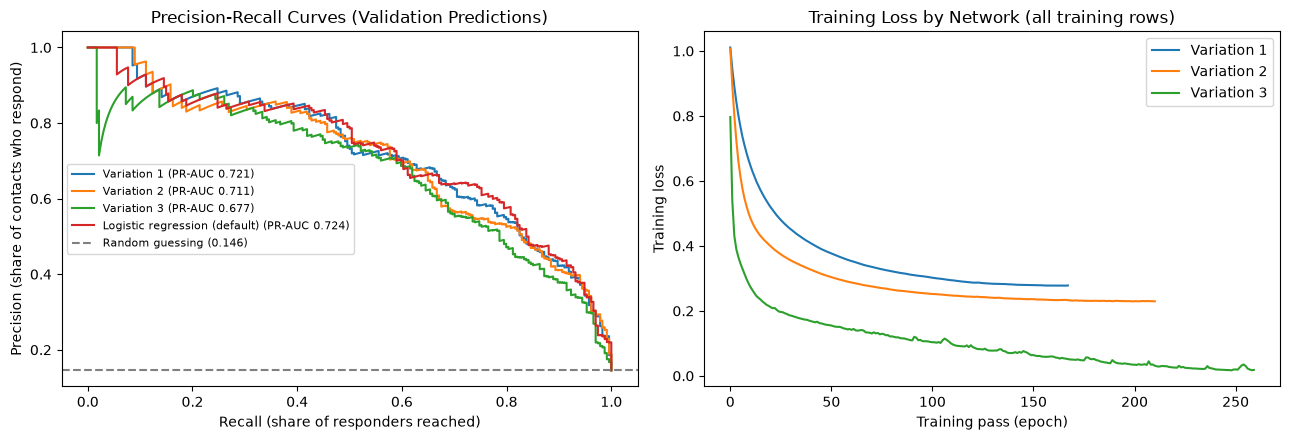

In [43]:
# Precision-recall curves from cross-validated predictions (each customer is scored by a
# model that did not see them), plus the training loss of each network
oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
curve_models = {**variations, reference_name: LogisticRegression(max_iter=2000)}
oof_prob7 = {name: cross_val_predict(m, X_model, y7, cv=oof_cv, method="predict_proba")[:, 1]
             for name, m in curve_models.items()}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, prob in oof_prob7.items():
    precision, recall, _ = precision_recall_curve(y7, prob)
    ax1.plot(recall, precision, label=f"{name} (PR-AUC {average_precision_score(y7, prob):.3f})")
ax1.axhline(y7.mean(), color="grey", linestyle="--", label=f"Random guessing ({y7.mean():.3f})")
ax1.set_xlabel("Recall (share of responders reached)"); ax1.set_ylabel("Precision (share of contacts who respond)")
ax1.set_title("Precision-Recall Curves (Validation Predictions)"); ax1.legend(fontsize=8)

for name, p in variations.items():
    fitted = clone(p).fit(X_model, y7)
    ax2.plot(fitted.named_steps["mlpclassifier"].loss_curve_, label=name)
ax2.set_xlabel("Training pass (epoch)"); ax2.set_ylabel("Training loss")
ax2.set_title("Training Loss by Network (all training rows)"); ax2.legend()
plt.tight_layout(); plt.show()

### 7.7 Best model of the week
The winner is the variation with the highest average **validation** PR-AUC. We also check the training-validation gap (how much it overfits) and compare it with the runner-up fold by fold, since validation scores vary across folds.

In [44]:
# Best variation by mean validation PR-AUC (the reference model is not a candidate)
candidates = list(variations)
best_name = comparison7.loc[candidates, "validation PR-AUC"].idxmax()
runner_up = comparison7.loc[[c for c in candidates if c != best_name], "validation PR-AUC"].idxmax()
diff = val7[best_name] - val7[runner_up]

print(f"Best variation: {best_name}")
print(f"  Validation PR-AUC {comparison7.loc[best_name, 'validation PR-AUC']:.3f}"
      f" | gap {comparison7.loc[best_name, 'gap (train - validation)']:.3f}")
print(f"  vs runner-up ({runner_up}, {comparison7.loc[runner_up, 'validation PR-AUC']:.3f}): "
      f"better on {(diff > 0).sum()} of 15 folds, mean difference {diff.mean():+.3f} "
      f"(fold-to-fold sd of the difference {diff.std():.3f})")
print(f"  vs Week 6 default logistic regression ({comparison7.loc[reference_name, 'validation PR-AUC']:.3f}): "
      f"better on {int(comparison7.loc[best_name, 'folds beating default LR (of 15)'])} of 15 folds")
print(f"  vs prior-campaign rule ({np.mean(rule_pr):.3f}): "
      f"{comparison7.loc[best_name, 'validation PR-AUC'] - np.mean(rule_pr):+.3f}")

# Save the winner, trained on the full training set, for later weeks (test set still untouched)
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
final7 = clone(variations[best_name]).fit(X_model, y7)
joblib.dump({"model": final7, "features": list(X_model.columns), "variation": best_name,
             "uses_order_features": use_sequence}, MODEL_DIR / "week7_best_model.joblib")
print("\nSaved:", MODEL_DIR / "week7_best_model.joblib")

Best variation: Variation 1
  Validation PR-AUC 0.725 | gap 0.054
  vs runner-up (Variation 2, 0.722): better on 7 of 15 folds, mean difference +0.003 (fold-to-fold sd of the difference 0.022)
  vs Week 6 default logistic regression (0.729): better on 6 of 15 folds
  vs prior-campaign rule (0.395): +0.330

Saved: ../models/week7_best_model.joblib


# Week 7- END